In [47]:
import urllib.request
url = "https://www.gutenberg.org/cache/epub/48320/pg48320.txt"
urllib.request.urlretrieve(url, "/content/sherlock_holmes.txt")
print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [48]:
with open("/content/sherlock_holmes.txt", "r", encoding="utf-8") as file:
    text = file.read()
print("Characters:", len(text))
print("\nFirst 500 characters:\n")
print(text[:500])

Characters: 595272

First 500 characters:

The Project Gutenberg eBook of Adventures of Sherlock Holmes
    
This eBook is for the use of anyone anywhere in the United States and
most other parts of the world at no cost and with almost no restrictions
whatsoever. You may copy it, give it away or re-use it under the terms
of the Project Gutenberg License included with this eBook or online
at www.gutenberg.org. If you are not located in the United States,
you will have to check the laws of the country where you are located
before using thi


In [49]:
# Inspect the beginning and end of the downloaded text
with open("/content/sherlock_holmes.txt", "r", encoding="utf-8") as file:
    raw_text = file.read()

print("===== DATASET OVERVIEW =====")
print("Total characters:", len(raw_text))
print("Total words:", len(raw_text.split()))

print("\n===== FIRST 1000 CHARACTERS =====")
print(raw_text[:1000])

print("\n===== LAST 1000 CHARACTERS =====")
print(raw_text[-1000:])

===== DATASET OVERVIEW =====
Total characters: 595272
Total words: 109467

===== FIRST 1000 CHARACTERS =====
The Project Gutenberg eBook of Adventures of Sherlock Holmes
    
This eBook is for the use of anyone anywhere in the United States and
most other parts of the world at no cost and with almost no restrictions
whatsoever. You may copy it, give it away or re-use it under the terms
of the Project Gutenberg License included with this eBook or online
at www.gutenberg.org. If you are not located in the United States,
you will have to check the laws of the country where you are located
before using this eBook.

Title: Adventures of Sherlock Holmes

Author: Arthur Conan Doyle


        
Release date: February 20, 2015 [eBook #48320]
                Most recently updated: October 24, 2024

Language: English

Other information and formats: www.gutenberg.org/ebooks/48320

Credits: Produced by The Online Distributed Proofreading Team at
        http://www.pgdp.net (This file was produced fr

In [50]:
# Step 3: Remove Project Gutenberg's front matter and back matter
start_marker = "*** START OF THE PROJECT GUTENBERG EBOOK"
end_marker = "*** END OF THE PROJECT GUTENBERG EBOOK"
start = raw_text.find(start_marker)
end = raw_text.find(end_marker)

if start == -1 or end == -1 or end <= start:
    print("Markers not found. Inspect the exact marker text before proceeding.")
else:
    # Keep the content after the start marker and before the end marker
    start = raw_text.find("\n", start)
    cleaned_text = raw_text[start:end].strip()

    print("Original characters:", len(raw_text))
    print("Cleaned characters:", len(cleaned_text))
    print("Cleaned words:", len(cleaned_text.split()))

    print("\n===== CLEANED TEXT PREVIEW =====")
    print(cleaned_text[:1000])

    print("\n===== CLEANED TEXT END =====")
    print(cleaned_text[-500:])

Original characters: 595272
Cleaned characters: 575741
Cleaned words: 106404

===== CLEANED TEXT PREVIEW =====
ADVENTURES OF SHERLOCK HOLMES




[Illustration:

  “THE GENTLEMAN IN THE PEW HANDED IT UP TO HER”
                                           [Page 238
]




  ADVENTURES
  OF
  SHERLOCK HOLMES

  BY
  A. CONAN DOYLE

  AUTHOR OF “MICAH CLARKE” ETC.

  ILLUSTRATED

  NEW YORK
  HARPER & BROTHERS, FRANKLIN SQUARE




  Copyright, 1892, by HARPER & BROTHERS.
  _All rights reserved._




CONTENTS


                                                 PAGE

     I.—A SCANDAL IN BOHEMIA                        3

    II.—THE RED-HEADED LEAGUE                      29

   III.—A CASE OF IDENTITY                         56

    IV.—THE BOSCOMBE VALLEY MYSTERY                76

     V.—THE FIVE ORANGE PIPS                      104

    VI.—THE MAN WITH THE TWISTED LIP              126

   VII.—THE ADVENTURE OF THE BLUE CARBUNCLE       153

  VIII.—THE ADVENTURE OF THE SPECKLED BAND        

In [51]:

# Find story headings and possible non-story sections

search_terms = [
    "A SCANDAL IN BOHEMIA",
    "THE RED-HEADED LEAGUE",
    "A CASE OF IDENTITY",
    "THE BOSCOMBE VALLEY MYSTERY",
    "THE FIVE ORANGE PIPS",
    "THE MAN WITH THE TWISTED LIP",
    "THE ADVENTURE OF THE BLUE CARBUNCLE",
    "THE ADVENTURE OF THE SPECKLED BAND",
    "THE ADVENTURE OF THE ENGINEER'S THUMB",
    "THE ADVENTURE OF THE NOBLE BACHELOR",
    "THE ADVENTURE OF THE BERYL CORONET",
    "THE ADVENTURE OF THE COPPER BEECHES",
    "Transcriber's Notes",
    "End of Project Gutenberg"
]

for term in search_terms:
    positions = []
    start_pos = 0

    while True:
        pos = cleaned_text.lower().find(term.lower(), start_pos)
        if pos == -1:
            break
        positions.append(pos)
        start_pos = pos + 1

    print(f"\n{term}: {positions[:6]}")

    # Display context around the last occurrence of each story title
    if "ADVENTURE" in term or term in [
        "A SCANDAL IN BOHEMIA",
        "THE RED-HEADED LEAGUE",
        "A CASE OF IDENTITY",
        "THE BOSCOMBE VALLEY MYSTERY",
        "THE FIVE ORANGE PIPS",
        "THE MAN WITH THE TWISTED LIP"
    ]:
        if len(positions) > 1:
            pos = positions[-1]
            print(repr(cleaned_text[max(0, pos-100):pos+150]))


A SCANDAL IN BOHEMIA: [462, 2333]
'LIGHTED THAT YOU HAVE COME’”               ″  \u2002 292\n\n\n\n\nADVENTURES OF SHERLOCK HOLMES\n\nAdventure I\n\nA SCANDAL IN BOHEMIA\n\n\nI\n\nTo Sherlock Holmes she is always _the_ woman. I have seldom heard\nhim mention her under any other name. In his eyes she ecli'

THE RED-HEADED LEAGUE: [517, 48923, 55512, 69692, 70763, 77335]
'ing had an experience which is in many ways unique,\nand by hearing the very remarkable narrative of the Red-headed League.”\n\n       *       *       *       *       *\n\n“You see, Watson,” he explained, in the early hours of the morning,\nas we sat over '

A CASE OF IDENTITY: [572, 98442]
'mme c’est rien—l’oeuvre c’est\ntout,’ as Gustave Flaubert wrote to Georges Sand.”\n\n\n\n\nAdventure III\n\nA CASE OF IDENTITY\n\n\n“My dear fellow,” said Sherlock Holmes, as we sat on either side\nof the fire in his lodgings at Baker Street, “life is infinitely'

THE BOSCOMBE VALLEY MYSTERY: [627, 136544]
'here is as\nmuch sense i

In [52]:
import re
story_heading_pattern = re.compile(
    r"(?m)^[ \t]*Adventure[ \t]+"
    r"(XII|XI|X|IX|VIII|VII|VI|V|IV|III|II|I)"
    r"[ \t]*$"
)
matches = list(story_heading_pattern.finditer(cleaned_text))
print("Story headings found:", len(matches))
for i, match in enumerate(matches, start=1):
    print(f"{i}. {match.group().strip()} — position {match.start()}")
assert len(matches) == 12, (
    f"Expected 12 story headings, but found {len(matches)}"
)
print("\nAll 12 story headings detected successfully!")

Story headings found: 12
1. Adventure I — position 2320
2. Adventure II — position 48909
3. Adventure III — position 98427
4. Adventure IV — position 136530
5. Adventure V — position 188081
6. Adventure VI — position 227693
7. Adventure VII — position 277031
8. Adventure VIII — position 319266
9. Adventure IX — position 372473
10. Adventure X — position 417191
11. Adventure XI — position 461473
12. Adventure XII — position 512594

All 12 story headings detected successfully!


In [53]:
# Step 6: Extract the 12 individual stories
story_texts = []
for i, match in enumerate(matches):
    start_pos = match.start()

    # Stop at the next story heading, or at the end of the book text
    if i + 1 < len(matches):
        end_pos = matches[i + 1].start()
    else:
        end_pos = cleaned_text.find("End of Project Gutenberg", start_pos)
        if end_pos == -1:
            end_pos = len(cleaned_text)

    story = cleaned_text[start_pos:end_pos].strip()
    story_texts.append(story)
print("Number of extracted stories:", len(story_texts))
for i, story in enumerate(story_texts, start=1):
    print(
        f"Story {i}: "
        f"{len(story):,} characters, "
        f"{len(story.split()):,} words"
    )
print("\n===== FIRST STORY PREVIEW =====")
print(story_texts[0][:600])
print("\n===== END OF TWELFTH STORY EXTRACT =====")
print(story_texts[-1][-1500:])

Number of extracted stories: 12
Story 1: 46,584 characters, 8,532 words
Story 2: 49,513 characters, 9,123 words
Story 3: 38,098 characters, 6,999 words
Story 4: 51,546 characters, 9,638 words
Story 5: 39,607 characters, 7,333 words
Story 6: 49,333 characters, 9,219 words
Story 7: 42,230 characters, 7,813 words
Story 8: 53,202 characters, 9,829 words
Story 9: 44,713 characters, 8,295 words
Story 10: 44,277 characters, 8,129 words
Story 11: 51,116 characters, 9,697 words
Story 12: 63,064 characters, 11,520 words

===== FIRST STORY PREVIEW =====
Adventure I

A SCANDAL IN BOHEMIA


I

To Sherlock Holmes she is always _the_ woman. I have seldom heard
him mention her under any other name. In his eyes she eclipses and
predominates the whole of her sex. It was not that he felt any emotion
akin to love for Irene Adler. All emotions, and that one particularly,
were abhorrent to his cold, precise, but admirably balanced mind. He
was, I take it, the most perfect reasoning and observing machine tha

In [54]:
import re
cleaned_stories = []
for i, story in enumerate(story_texts):
    story = story.strip()
    # Remove Project Gutenberg correction notes from the final story.
    if i == len(story_texts) - 1:
        correction_match = re.search(
            r"(?m)^[ \t]*Page[ \t]+\d+[ \t]*\n"
            r"(?:(?!^[ \t]*Page[ \t]+\d+[ \t]*$).*\n)*?"
            r".*_changed to_",
            story
        )
        if correction_match:
            story = story[:correction_match.start()].rstrip()
            print("Removed the proofreading notes from Story 12.")
        else:
            print("Correction-note marker not detected; inspect Story 12's ending.")
    # Remove the artificial extraction heading, e.g. "Adventure I".
    story = re.sub(
        r"^Adventure[ \t]+(?:XII|XI|IX|VIII|VII|VI|IV|III|II|X|V|I)[ \t]*\n+",
        "",
        story,
        count=1
    )
    # Normalize excessive blank lines and surrounding whitespace.
    story = re.sub(r"\n{3,}", "\n\n", story)
    story = story.strip()

    cleaned_stories.append(story)
print("\nCleaned dataset summary")
print("=======================")
print("Number of stories:", len(cleaned_stories))
print("Total characters:", f"{sum(len(s) for s in cleaned_stories):,}")
print("Total whitespace-separated words:",
      f"{sum(len(s.split()) for s in cleaned_stories):,}")
for i, story in enumerate(cleaned_stories, start=1):
    print(f"Story {i}: {len(story.split()):,} words")
print("\n===== CLEANED STORY 1 PREVIEW =====")
print(cleaned_stories[0][:500])

print("\n===== CLEANED STORY 12 ENDING =====")
print(cleaned_stories[-1][-500:])

Removed the proofreading notes from Story 12.

Cleaned dataset summary
Number of stories: 12
Total characters: 571,406
Total whitespace-separated words: 105,832
Story 1: 8,530 words
Story 2: 9,121 words
Story 3: 6,997 words
Story 4: 9,636 words
Story 5: 7,331 words
Story 6: 9,217 words
Story 7: 7,811 words
Story 8: 9,827 words
Story 9: 8,293 words
Story 10: 8,127 words
Story 11: 9,695 words
Story 12: 11,247 words

===== CLEANED STORY 1 PREVIEW =====
A SCANDAL IN BOHEMIA

I

To Sherlock Holmes she is always _the_ woman. I have seldom heard
him mention her under any other name. In his eyes she eclipses and
predominates the whole of her sex. It was not that he felt any emotion
akin to love for Irene Adler. All emotions, and that one particularly,
were abhorrent to his cold, precise, but admirably balanced mind. He
was, I take it, the most perfect reasoning and observing machine that
the world has seen; but, as a lover, he would have placed him

===== CLEANED STORY 12 ENDING =====
he most 

In [55]:

# Step 8: Remove publisher information and remaining back matter

final_story = cleaned_stories[-1]

back_matter_patterns = [
    r"(?i)PUBLISHED BY HARPER\s*&\s*BROTHERS",
    r"(?i)Transcriber[’']s Note\s*:"
]

cut_positions = [
    match.start()
    for pattern in back_matter_patterns
    if (match := re.search(pattern, final_story))
]

if cut_positions:
    final_story = final_story[:min(cut_positions)].rstrip()
    cleaned_stories[-1] = final_story
    print("Removed remaining publisher/back matter.")
else:
    print("No remaining back-matter marker detected.")

# Verify the cleaned corpus
print("\n===== FINAL DATASET CHECK =====")
print("Number of stories:", len(cleaned_stories))
print("Total characters:", f"{sum(len(s) for s in cleaned_stories):,}")
print("Total whitespace-separated words:",
      f"{sum(len(s.split()) for s in cleaned_stories):,}")

print("\n===== END OF STORY 12 =====")
print(cleaned_stories[-1][-700:])

# Basic validation
assert len(cleaned_stories) == 12
assert all(len(story.strip()) > 0 for story in cleaned_stories)

print("\nValidation passed: 12 non-empty stories.")


Removed remaining publisher/back matter.

===== FINAL DATASET CHECK =====
Number of stories: 12
Total characters: 564,468
Total whitespace-separated words: 104,718

===== END OF STORY 12 =====
loth, $1 50; Paper, 75 cents.

  APRIL HOPES. A Novel. 12mo, Cloth, $1 50; Paper, 75 cents.

  CHRISTMAS EVERY DAY, AND OTHER STORIES. Illustrated. Post 8vo,
    Cloth, $1 25.

  A BOY’S TOWN. Illustrated. Post 8vo, Cloth, $1 25.

  CRITICISM AND FICTION. With Portrait. 16mo, Cloth, $1 00.

  MODERN ITALIAN POETS. With Portraits. 12mo, Half Cloth, $2 00.

  THE MOUSE-TRAP, AND OTHER FARCES. Illustrated. 12mo, Cloth,
    $1 00.

  A LETTER OF INTRODUCTION. A Farce. Illustrated. 32mo, Cloth,
    50 cents.

  A LITTLE SWISS SOJOURN. Illustrated. 32mo, Cloth, 50 cents.

  THE ALBANY DEPOT. A Farce. Illustrated. 32mo, Cloth, 50 cents.

  THE GARROTERS. A Farce. Illustrated. 32mo, Cloth, 50 cents.

Validation passed: 12 non-empty stories.


In [56]:
# Diagnose where Story 12's actual narrative ends
final_story = cleaned_stories[-1]
for phrase in [
    "THE ADVENTURE OF THE COPPER BEECHES",
    "PUBLISHED BY HARPER",
    "Transcriber's Note:",
    "Transcriber’s Note:",
    "THE MOUSE-TRAP, AND OTHER FARCES"
]:
    position = final_story.lower().find(phrase.lower())
    print(f"\n{phrase!r}: position = {position}")

    if position != -1:
        print(final_story[max(0, position - 250):position + 350])


'THE ADVENTURE OF THE COPPER BEECHES': position = 0
THE ADVENTURE OF THE COPPER BEECHES

“To the man who loves art for its own sake,” remarked Sherlock Holmes,
tossing aside the advertisement sheet of _The Daily Telegraph_, “it is
frequently in its least important and lowliest manifestations that the
keenest pleasure is to be derived. It is pleasant to me to observe,
Watson, that you have so far gra

'PUBLISHED BY HARPER': position = -1

"Transcriber's Note:": position = -1

'Transcriber’s Note:': position = -1

'THE MOUSE-TRAP, AND OTHER FARCES': position = 54077
 DAY, AND OTHER STORIES. Illustrated. Post 8vo,
    Cloth, $1 25.

  A BOY’S TOWN. Illustrated. Post 8vo, Cloth, $1 25.

  CRITICISM AND FICTION. With Portrait. 16mo, Cloth, $1 00.

  MODERN ITALIAN POETS. With Portraits. 12mo, Half Cloth, $2 00.

  THE MOUSE-TRAP, AND OTHER FARCES. Illustrated. 12mo, Cloth,
    $1 00.

  A LETTER OF INTRODUCTION. A Farce. Illustrated. 32mo, Cloth,
    50 cents.

  A LITTLE SWISS SOJOURN. Il

In [57]:

# Remove the publisher catalogue from the end of Story 12.

final_story = cleaned_stories[-1]

catalogue_marker = "THE MOUSE-TRAP, AND OTHER FARCES"
catalogue_position = final_story.find(catalogue_marker)

if catalogue_position != -1:
    # Find the start of the catalogue entry's line.
    line_start = final_story.rfind("\n", 0, catalogue_position) + 1
    cleaned_stories[-1] = final_story[:line_start].rstrip()
    print("Removed the publisher catalogue.")
else:
    print("Catalogue marker not found. No changes made.")

print("\n===== VERIFIED STORY 12 ENDING =====")
print(cleaned_stories[-1][-700:])

print("\n===== UPDATED DATASET SUMMARY =====")
print("Number of stories:", len(cleaned_stories))
print("Total characters:", f"{sum(len(s) for s in cleaned_stories):,}")
print("Total whitespace-separated words:",
      f"{sum(len(s.split()) for s in cleaned_stories):,}")

assert len(cleaned_stories) == 12
assert "THE MOUSE-TRAP, AND OTHER FARCES" not in cleaned_stories[-1]

print("\nValidation passed.")


Removed the publisher catalogue.

===== VERIFIED STORY 12 ENDING =====


  THE QUALITY OF MERCY. A Novel. 12mo, Cloth, $1 50; Paper,
    75 cents.

  AN IMPERATIVE DUTY. A Novel. 12mo, Cloth, $1 00.

  A HAZARD OF NEW FORTUNES. A Novel. 2 Volumes. 12mo, Cloth,
    $2 00; Illustrated. 12mo, Paper, $1 00.

  THE SHADOW OF A DREAM. A Story. 12mo, Cloth, $1 00; Paper,
    50 cents.

  ANNIE KILBURN. A Novel. 12mo, Cloth, $1 50; Paper, 75 cents.

  APRIL HOPES. A Novel. 12mo, Cloth, $1 50; Paper, 75 cents.

  CHRISTMAS EVERY DAY, AND OTHER STORIES. Illustrated. Post 8vo,
    Cloth, $1 25.

  A BOY’S TOWN. Illustrated. Post 8vo, Cloth, $1 25.

  CRITICISM AND FICTION. With Portrait. 16mo, Cloth, $1 00.

  MODERN ITALIAN POETS. With Portraits. 12mo, Half Cloth, $2 00.

===== UPDATED DATASET SUMMARY =====
Number of stories: 12
Total characters: 564,124
Total whitespace-separated words: 104,669

Validation passed.


In [58]:
final_story = cleaned_stories[-1]

# Show the final story in sections near its end.
# This helps us locate the transition from the story to publisher material.
print("Total characters in Story 12:", len(final_story))

for phrase in [
    "THE ADVENTURE OF THE COPPER BEECHES",
    "THE QUALITY OF MERCY",
    "PUBLISHED BY",
    "Harper & Brothers",
    "NEW YORK"
]:
    position = final_story.lower().find(phrase.lower())
    print(f"{phrase!r}: {position}")

print("\n===== TEXT AROUND THE FIRST CATALOGUE ENTRY =====")
print(final_story[45000:47000])

print("\n===== TEXT AROUND THE END OF THE NARRATIVE =====")
print(final_story[35000:37000])


Total characters in Story 12: 54073
'THE ADVENTURE OF THE COPPER BEECHES': 0
'THE QUALITY OF MERCY': 53377
'PUBLISHED BY': -1
'Harper & Brothers': -1
'NEW YORK': -1

===== TEXT AROUND THE FIRST CATALOGUE ENTRY =====

their power.”

“I am sure that you are right, Mr. Holmes,” cried our client. “A
thousand things come back to me which make me certain that you have
hit it. Oh, let us lose not an instant in bringing help to this poor
creature.”

“We must be circumspect, for we are dealing with a very cunning man. We
can do nothing until seven o’clock. At that hour we shall be with you,
and it will not be long before we solve the mystery.”

We were as good as our word, for it was just seven when we reached the
Copper Beeches, having put up our trap at a way-side public-house. The
group of trees, with their dark leaves shining like burnished metal in
the light of the setting sun, were sufficient to mark the house even
had Miss Hunter not been standing smiling on the door-step.

“Have you man

In [59]:
final_story = cleaned_stories[-1]
# Inspect the transition into publisher catalogue material
catalogue_position = final_story.find("THE QUALITY OF MERCY")

print("Catalogue marker position:", catalogue_position)
print("\n===== TEXT BEFORE CATALOGUE =====")
print(final_story[catalogue_position - 3000:catalogue_position])

print("\n===== TEXT AFTER CATALOGUE START =====")
print(final_story[catalogue_position:catalogue_position + 1200])

Catalogue marker position: 53377

===== TEXT BEFORE CATALOGUE =====
ied again. She was slighted like, and had no say in
anything; but it never really became bad for her until after she met
Mr. Fowler at a friend’s house. As well as I could learn, Miss Alice
had rights of her own by will, but she was so quiet and patient, she
was, that she never said a word about them, but just left everything in
Mr. Rucastle’s hands. He knew he was safe with her; but when there was
a chance of a husband coming forward, who would ask for all that the
law would give him, then her father thought it time to put a stop on
it. He wanted her to sign a paper, so that whether she married or not,
he could use her money. When she wouldn’t do it, he kept on worrying
her until she got brain-fever, and for six weeks was at death’s door.
Then she got better at last, all worn to a shadow, and with her
beautiful hair cut off; but that didn’t make no change in her young
man, and he stuck to her as true as man could be.”

In [60]:

# Trim Story 12 after its actual narrative ending.

final_story = cleaned_stories[-1]

ending_marker = "BY W. D. HOWELLS."
ending_position = final_story.find(ending_marker)

if ending_position != -1:
    cleaned_stories[-1] = final_story[:ending_position].rstrip()
    print("Removed publisher catalogue after the story ending.")
else:
    print("Ending marker not found. Inspect the story ending before proceeding.")

# Verify the final story
print("\n===== FINAL STORY ENDING =====")
print(cleaned_stories[-1][-500:])

# Validate the dataset
assert len(cleaned_stories) == 12
assert "THE QUALITY OF MERCY" not in cleaned_stories[-1]
assert "THE END" in cleaned_stories[-1][-1000:]

combined_text = "\n\n".join(cleaned_stories)

print("\n===== FINAL DATASET SUMMARY =====")
print("Stories:", len(cleaned_stories))
print("Characters:", f"{len(combined_text):,}")
print("Whitespace-separated words:",
      f"{sum(len(s.split()) for s in cleaned_stories):,}")

# Save files
import os

output_dir = "/content/sherlock_dataset"
os.makedirs(output_dir, exist_ok=True)

with open(
    os.path.join(output_dir, "sherlock_holmes_corpus.txt"),
    "w",
    encoding="utf-8"
) as f:
    f.write(combined_text)

with open(
    os.path.join(output_dir, "sherlock_holmes_stories.txt"),
    "w",
    encoding="utf-8"
) as f:
    for i, story in enumerate(cleaned_stories, start=1):
        f.write(f"STORY {i}\n\n{story}\n\n")

print("\nSaved corpus and individual-story files in:", output_dir)


Removed publisher catalogue after the story ending.

===== FINAL STORY ENDING =====
 from them.
Mr. Fowler and Miss Rucastle were married, by special license, in
Southampton the day after their flight, and he is now the holder of a
Government appointment in the Island of Mauritius. As to Miss Violet
Hunter, my friend Holmes, rather to my disappointment, manifested no
further interest in her when once she had ceased to be the centre of
one of his problems, and she is now the head of a private school at
Walsall, where I believe that she has met with considerable success.

THE END

===== FINAL DATASET SUMMARY =====
Stories: 12
Characters: 563,427
Whitespace-separated words: 104,549

Saved corpus and individual-story files in: /content/sherlock_dataset


#Dataset cleaning done. Tokenizing data now

In [61]:
import os
import re
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer

corpus_path = "/content/sherlock_dataset/sherlock_holmes_corpus.txt"

with open(corpus_path, "r", encoding="utf-8") as file:
    combined_text = file.read()

print("TensorFlow version:", tf.__version__)
print("Characters:", len(combined_text))
print("Words:", len(combined_text.split()))
print("\nText preview:\n")
print(combined_text[:500])


TensorFlow version: 2.21.0
Characters: 563427
Words: 104549

Text preview:

A SCANDAL IN BOHEMIA

I

To Sherlock Holmes she is always _the_ woman. I have seldom heard
him mention her under any other name. In his eyes she eclipses and
predominates the whole of her sex. It was not that he felt any emotion
akin to love for Irene Adler. All emotions, and that one particularly,
were abhorrent to his cold, precise, but admirably balanced mind. He
was, I take it, the most perfect reasoning and observing machine that
the world has seen; but, as a lover, he would have placed him


In [62]:

words = combined_text.split()

total_words = len(words)
train_end = int(total_words * 0.80)
val_end = int(total_words * 0.90)

train_words = words[:train_end]
val_words = words[train_end:val_end]
test_words = words[val_end:]

train_text = " ".join(train_words)
val_text = " ".join(val_words)
test_text = " ".join(test_words)

print("Total words:", total_words)
print("Training words:", len(train_words))
print("Validation words:", len(val_words))
print("Test words:", len(test_words))


Total words: 104549
Training words: 83639
Validation words: 10455
Test words: 10455


In [63]:

import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer

VOCAB_SIZE = 10000

tokenizer = Tokenizer(
    num_words=VOCAB_SIZE,
    oov_token="<OOV>",
    filters='!"#$%&()*+,-./:;=?@[\\]^_`{|}~\t\n'
)

# Learn vocabulary using training text only
tokenizer.fit_on_texts([train_text])

# Convert each split into numerical word IDs
train_tokens = tokenizer.texts_to_sequences([train_text])[0]
val_tokens = tokenizer.texts_to_sequences([val_text])[0]
test_tokens = tokenizer.texts_to_sequences([test_text])[0]

# Actual output vocabulary size, including OOV and padding
vocab_size = min(VOCAB_SIZE, len(tokenizer.word_index) + 1)

print("Unique words learned:", len(tokenizer.word_index))
print("Vocabulary size used by models:", vocab_size)
print("Training tokens:", len(train_tokens))
print("Validation tokens:", len(val_tokens))
print("Test tokens:", len(test_tokens))

print("\nSample word-to-ID mappings:")
for word in ["sherlock", "holmes", "watson", "the"]:
    print(f"{word}: {tokenizer.word_index.get(word, 'not found')}")


Unique words learned: 7808
Vocabulary size used by models: 7809
Training tokens: 86688
Validation tokens: 10767
Test tokens: 10737

Sample word-to-ID mappings:
sherlock: 121
holmes: 33
watson: 148
the: 2


In [64]:

oov_id = tokenizer.word_index["<OOV>"]

for split_name, tokens in [
    ("Training", train_tokens),
    ("Validation", val_tokens),
    ("Test", test_tokens)
]:
    oov_count = sum(token == oov_id for token in tokens)
    oov_percentage = (
        100 * oov_count / len(tokens) if tokens else 0
    )

    print(
        f"{split_name}: {oov_count:,} OOV tokens "
        f"({oov_percentage:.2f}%)"
    )


Training: 0 OOV tokens (0.00%)
Validation: 472 OOV tokens (4.38%)
Test: 645 OOV tokens (6.01%)


In [65]:
SEQ_LENGTH = 20
def create_sequences(token_ids, seq_length):
    X = []
    y = []

    for i in range(seq_length, len(token_ids)):
        X.append(token_ids[i - seq_length:i])
        y.append(token_ids[i])

    return np.array(X, dtype=np.int32), np.array(y, dtype=np.int32)

X_train, y_train = create_sequences(train_tokens, SEQ_LENGTH)
X_val, y_val = create_sequences(val_tokens, SEQ_LENGTH)
X_test, y_test = create_sequences(test_tokens, SEQ_LENGTH)

print("Training inputs:", X_train.shape)
print("Training targets:", y_train.shape)

print("Validation inputs:", X_val.shape)
print("Validation targets:", y_val.shape)

print("Test inputs:", X_test.shape)
print("Test targets:", y_test.shape)

Training inputs: (86668, 20)
Training targets: (86668,)
Validation inputs: (10747, 20)
Validation targets: (10747,)
Test inputs: (10717, 20)
Test targets: (10717,)


In [66]:

index_to_word = tokenizer.index_word

def decode_tokens(token_ids):
    return " ".join(index_to_word.get(int(token_id), "<UNK>") for token_id in token_ids)

sample_index = 0

print("Input sequence:")
print(decode_tokens(X_train[sample_index]))

print("\nActual next word (target):")
print(index_to_word.get(int(y_train[sample_index]), "<UNK>"))

print("\nInput shape:", X_train[sample_index].shape)
print("Target ID:", y_train[sample_index])


Input sequence:
a scandal in bohemia i to sherlock holmes she is always the woman i have seldom heard him mention her

Actual next word (target):
under

Input shape: (20,)
Target ID: 300


In [67]:

import pickle

processed_dir = "/content/sherlock_dataset/processed"
os.makedirs(processed_dir, exist_ok=True)

np.savez_compressed(
    os.path.join(processed_dir, "next_word_sequences.npz"),
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    X_test=X_test,
    y_test=y_test
)

with open(os.path.join(processed_dir, "tokenizer.pkl"), "wb") as file:
    pickle.dump(tokenizer, file)

print("Processed arrays and tokenizer saved to:", processed_dir)
print(f"Training examples: {len(X_train):,}")
print(f"Validation examples: {len(X_val):,}")
print(f"Test examples: {len(X_test):,}")
print(f"Vocabulary size: {vocab_size:,}")
print(f"Context length: {SEQ_LENGTH}")
print(f"Approximate X_train memory: {X_train.nbytes / (1024**2):.2f} MB")


Processed arrays and tokenizer saved to: /content/sherlock_dataset/processed
Training examples: 86,668
Validation examples: 10,747
Test examples: 10,717
Vocabulary size: 7,809
Context length: 20
Approximate X_train memory: 6.61 MB


In [68]:

BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .shuffle(20000, seed=42)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_dataset = (
    tf.data.Dataset.from_tensor_slices((X_val, y_val))
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_dataset = (
    tf.data.Dataset.from_tensor_slices((X_test, y_test))
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Training batches:", tf.data.experimental.cardinality(train_dataset).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_dataset).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_dataset).numpy())

# Inspect one batch
for X_batch, y_batch in train_dataset.take(1):
    print("\nInput batch shape:", X_batch.shape)
    print("Target batch shape:", y_batch.shape)


Training batches: 1355
Validation batches: 168
Test batches: 168

Input batch shape: (64, 20)
Target batch shape: (64,)


In [69]:

EMBEDDING_DIM = 128
RNN_UNITS = 128
LEARNING_RATE = 0.001
EPOCHS = 10

print("Vocabulary size:", vocab_size)
print("Sequence length:", SEQ_LENGTH)
print("Embedding dimension:", EMBEDDING_DIM)
print("Recurrent units:", RNN_UNITS)
print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", EPOCHS)


Vocabulary size: 7809
Sequence length: 20
Embedding dimension: 128
Recurrent units: 128
Batch size: 64
Maximum epochs: 10


In [70]:

from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import (
    Embedding, SimpleRNN, Bidirectional, LSTM, GRU, Dense
)
from tensorflow.keras.optimizers import Adam

def build_model(model_type):
    model = Sequential(
        name=f"{model_type}_next_word_model",
        layers=[
            Input(shape=(SEQ_LENGTH,), dtype="int32"),
            Embedding(
                input_dim=vocab_size,
                output_dim=EMBEDDING_DIM
            )
        ]
    )

    if model_type == "SimpleRNN":
        model.add(SimpleRNN(RNN_UNITS))

    elif model_type == "BiRNN":
        model.add(Bidirectional(SimpleRNN(RNN_UNITS)))

    elif model_type == "LSTM":
        model.add(LSTM(RNN_UNITS))

    elif model_type == "GRU":
        model.add(GRU(RNN_UNITS))

    else:
        raise ValueError(f"Unknown model type: {model_type}")

    model.add(Dense(vocab_size, activation="softmax"))

    model.compile(
        optimizer=Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["sparse_categorical_accuracy"]
    )

    return model


# Build and inspect the Simple RNN
model = build_model("SimpleRNN")
model.summary()

print("\nModel input shape:", model.input_shape)
print("Model output shape:", model.output_shape)
print("Total parameters:", model.count_params())


Model: "SimpleRNN_next_word_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 20, 128)        │       999,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7809)           │     1,007,361 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,039,809 (7.78 MB)

 Trainable params: 2,039,809 (7.78 MB)

 Non-trainable params: 0 (0.00 B)


Model input shape: (None, 20)
Model output shape: (None, 7809)
Total parameters: 2039809


In [71]:
test_model = build_model("SimpleRNN")
history_test = test_model.fit(
    train_dataset.take(100),
    validation_data=val_dataset.take(20),
    epochs=1,
    verbose=1
)

print("\nTest-run training loss:",
      history_test.history["loss"][-1])

print("Test-run validation loss:",
      history_test.history["val_loss"][-1])

100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 7.1933 - sparse_categorical_accuracy: 0.0353 - val_loss: 6.8085 - val_sparse_categorical_accuracy: 0.0305

Test-run training loss: 7.193277359008789
Test-run validation loss: 6.80850076675415


In [72]:

import time
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

SEED = 42
tf.keras.utils.set_random_seed(SEED)

def get_callbacks():
    return [
        EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True,
            verbose=1
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=1,
            min_lr=1e-5,
            verbose=1
        )
    ]

print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("Callbacks configured.")


GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Callbacks configured.


In [73]:

MODEL_TYPES = ["SimpleRNN", "BiRNN", "LSTM", "GRU"]

EPOCHS = 10

results = {}
histories = {}
trained_models = {}

model_dir = "/content/sherlock_dataset/models"
os.makedirs(model_dir, exist_ok=True)

for model_type in MODEL_TYPES:
    print("\n" + "=" * 60)
    print(f"Training model: {model_type}")
    print("=" * 60)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    current_model = build_model(model_type)

    start_time = time.time()

    history = current_model.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=EPOCHS,
        callbacks=get_callbacks(),
        verbose=1
    )

    elapsed_time = time.time() - start_time

    # Early stopping restores the best validation-loss weights
    model_path = os.path.join(model_dir, f"{model_type}.keras")
    current_model.save(model_path)

    best_epoch = int(np.argmin(history.history["val_loss"])) + 1

    results[model_type] = {
        "training_time_seconds": elapsed_time,
        "best_epoch": best_epoch,
        "best_val_loss": min(history.history["val_loss"]),
        "best_val_accuracy": max(history.history["val_sparse_categorical_accuracy"])
    }

    histories[model_type] = history.history
    trained_models[model_type] = current_model

    print(f"\n{model_type} training time: {elapsed_time / 60:.2f} minutes")
    print(f"Best epoch: {best_epoch}")
    print(f"Best validation loss: {results[model_type]['best_val_loss']:.4f}")
    print(f"Best validation accuracy: {results[model_type]['best_val_accuracy']:.4f}")

print("\nAll four models have finished training.")



Training model: SimpleRNN
Epoch 1/10
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - loss: 6.5226 - sparse_categorical_accuracy: 0.0631 - val_loss: 6.0741 - val_sparse_categorical_accuracy: 0.0858 - learning_rate: 0.0010
Epoch 2/10
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 5.6741 - sparse_categorical_accuracy: 0.1127 - val_loss: 5.7378 - val_sparse_categorical_accuracy: 0.1242 - learning_rate: 0.0010
Epoch 3/10
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 5.2183 - sparse_categorical_accuracy: 0.1421 - val_loss: 5.6964 - val_sparse_categorical_accuracy: 0.1302 - learning_rate: 0.0010
Epoch 4/10
1351/1355 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 4.8852 - sparse_categorical_accuracy: 0.1616
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 4.8537 - sparse_categorical_accuracy: 0.1648 - val_loss: 5.7058 - val_sparse_categorical_accuracy: 0.1359 - learning_rate: 0.0010
Epoch 5/10
1355/1355 ━━━━━━━━━━━

In [74]:
training_results_df = pd.DataFrame(results).T
training_results_df["training_time_minutes"] = (
    training_results_df["training_time_seconds"] / 60
)

display(
    training_results_df[
        [
            "training_time_minutes",
            "best_epoch",
            "best_val_loss",
            "best_val_accuracy"
        ]
    ].round(4)
)


,training_time_minutes,best_epoch,best_val_loss,best_val_accuracy
SimpleRNN,0.5782,3.0,5.6964,0.1389
BiRNN,0.7088,2.0,5.7143,0.1313
LSTM,0.9948,4.0,5.7260,0.1376
GRU,0.8515,3.0,5.6225,0.1438


In [75]:

import time
import numpy as np
import pandas as pd

test_results = {}

for model_type in MODEL_TYPES:
    print(f"Evaluating {model_type}...")

    current_model = trained_models[model_type]

    start_time = time.time()

    test_loss, test_accuracy = current_model.evaluate(
        test_dataset,
        verbose=0
    )

    evaluation_time = time.time() - start_time

    # Perplexity = exp(cross-entropy loss)
    perplexity = float(np.exp(test_loss))

    test_results[model_type] = {
        "test_loss": float(test_loss),
        "test_perplexity": perplexity,
        "test_accuracy": float(test_accuracy),
        "evaluation_time_seconds": evaluation_time
    }

    print(
        f"Loss: {test_loss:.4f} | "
        f"Perplexity: {perplexity:.2f} | "
        f"Accuracy: {test_accuracy:.4f}"
    )

test_results_df = pd.DataFrame(test_results).T
test_results_df["test_accuracy_percent"] = (
    test_results_df["test_accuracy"] * 100
)

print("\n===== FINAL TEST RESULTS =====")
display(
    test_results_df[
        [
            "test_loss",
            "test_perplexity",
            "test_accuracy_percent",
            "evaluation_time_seconds"
        ]
    ].round(4)
)


Evaluating SimpleRNN...
Loss: 5.8583 | Perplexity: 350.12 | Accuracy: 0.1308
Evaluating BiRNN...
Loss: 5.8583 | Perplexity: 350.13 | Accuracy: 0.1228
Evaluating LSTM...
Loss: 5.9084 | Perplexity: 368.13 | Accuracy: 0.1305
Evaluating GRU...
Loss: 5.7861 | Perplexity: 325.74 | Accuracy: 0.1357

===== FINAL TEST RESULTS =====


,test_loss,test_perplexity,test_accuracy_percent,evaluation_time_seconds
SimpleRNN,5.8583,350.1160,13.0820,0.9670
BiRNN,5.8583,350.1345,12.2796,1.1750
LSTM,5.9084,368.1343,13.0540,0.8997
GRU,5.7861,325.7366,13.5672,0.8103


In [76]:

results_dir = "/content/sherlock_dataset/results"
os.makedirs(results_dir, exist_ok=True)

test_results_df.to_csv(
    os.path.join(results_dir, "test_results.csv"),
    index=True,
    index_label="model"
)

training_results_df.to_csv(
    os.path.join(results_dir, "training_results.csv"),
    index=True,
    index_label="model"
)

print("Saved results to:", results_dir)
print("Files:")
print("- test_results.csv")
print("- training_results.csv")


Saved results to: /content/sherlock_dataset/results
Files:
- test_results.csv
- training_results.csv


#Diff temps

In [77]:

import numpy as np
import tensorflow as tf

def generate_text(model, seed_text, temperature=1.0, num_words=60):
    if temperature <= 0:
        raise ValueError("Temperature must be greater than 0.")

    generated_words = seed_text.lower().split()

    for _ in range(num_words):
        # Convert the current text context into token IDs
        token_sequence = tokenizer.texts_to_sequences(
            [" ".join(generated_words)]
        )[0]

        # Use only the last SEQ_LENGTH tokens
        token_sequence = token_sequence[-SEQ_LENGTH:]

        # Left-pad shorter contexts to the required length
        if len(token_sequence) < SEQ_LENGTH:
            token_sequence = (
                [0] * (SEQ_LENGTH - len(token_sequence))
                + token_sequence
            )

        input_array = np.array([token_sequence], dtype=np.int32)

        # Predict next-word probabilities
        predictions = model.predict(input_array, verbose=0)[0]

        # Apply temperature scaling
        predictions = np.asarray(predictions, dtype=np.float64)
        predictions = np.log(np.maximum(predictions, 1e-10))
        predictions = predictions / temperature

        # Stable softmax
        predictions = predictions - np.max(predictions)
        probabilities = np.exp(predictions)
        probabilities = probabilities / np.sum(probabilities)

        # Sample the next token
        next_token = np.random.choice(
            len(probabilities),
            p=probabilities
        )

        # Avoid padding token 0
        if next_token == 0:
            next_token = int(np.argmax(probabilities))

        next_word = tokenizer.index_word.get(
            int(next_token), "<OOV>"
        )

        generated_words.append(next_word)

    return " ".join(generated_words)


In [78]:

seed_prompts = [
    "Sherlock Holmes looked at the stranger",
    "I had been watching Holmes",
    "The room was silent and"
]

for i, seed in enumerate(seed_prompts, start=1):
    print(f"Seed {i}: {seed}")


Seed 1: Sherlock Holmes looked at the stranger
Seed 2: I had been watching Holmes
Seed 3: The room was silent and


In [79]:

TEMPERATURES = [0.5, 1.0, 1.3]
NUM_GENERATED_WORDS = 60

generation_results = []

for model_type in MODEL_TYPES:
    current_model = trained_models[model_type]

    for seed in seed_prompts:
        for temperature in TEMPERATURES:
            # Reset seed for reproducibility
            np.random.seed(42)

            generated = generate_text(
                model=current_model,
                seed_text=seed,
                temperature=temperature,
                num_words=NUM_GENERATED_WORDS
            )

            generation_results.append({
                "model": model_type,
                "seed_prompt": seed,
                "temperature": temperature,
                "generated_text": generated
            })

print("Total generated samples:", len(generation_results))


Total generated samples: 36


In [80]:

for model_type in MODEL_TYPES:
    print("\n" + "=" * 70)
    print("MODEL:", model_type)
    print("=" * 70)

    for temperature in TEMPERATURES:
        sample = next(
            item for item in generation_results
            if item["model"] == model_type
            and item["seed_prompt"] == seed_prompts[0]
            and item["temperature"] == temperature
        )

        print(f"\nTemperature: {temperature}")
        print(sample["generated_text"])



MODEL: SimpleRNN

Temperature: 0.5
sherlock holmes looked at the stranger and gave me to the way of a light of the levers in the room and the colonel was a small man and was a light and was a very thin and and stood back up and the death of the corridor the passage and was a small hat and hurried into his head and hurried of the room and

Temperature: 1.0
sherlock holmes looked at the stranger of tinged if you have been me use me ’ i ruefully “holmes i had on his interesting point i met to well from which found to tell me and then i have communicated committed by i have written it was off the exercise is people ” sherlock holmes so hedges “my sliding dreamy law i’ll have not a hour

Temperature: 1.3
sherlock holmes looked at the stranger so exchanging soothing brandy to our last “cooee turned light the exercising recognizing short “oh were away however from her valley is little neville floor ‘first to serpentine dreadful “you understand ” he restless fleeting motioned that in india wh

In [81]:

generation_df = pd.DataFrame(generation_results)

generation_path = os.path.join(
    results_dir, "generated_samples.csv"
)

generation_df.to_csv(generation_path, index=False)

print("Saved generated samples to:", generation_path)
print("Number of samples:", len(generation_df))
display(generation_df.head(6))


Saved generated samples to: /content/sherlock_dataset/results/generated_samples.csv
Number of samples: 36


,model,seed_prompt,temperature,generated_text
0,SimpleRNN,Sherlock Holmes looked at the stranger,0.5,sherlock holmes looked at the stranger and gav...
1,SimpleRNN,Sherlock Holmes looked at the stranger,1.0,sherlock holmes looked at the stranger of ting...
2,SimpleRNN,Sherlock Holmes looked at the stranger,1.3,sherlock holmes looked at the stranger so exch...
3,SimpleRNN,I had been watching Holmes,0.5,i had been watching holmes and took in the roo...
4,SimpleRNN,I had been watching Holmes,1.0,i had been watching holmes at lurid questions ...
5,SimpleRNN,I had been watching Holmes,1.3,i had been watching holmes these ajar decoyed ...


In [82]:

from collections import Counter

def calculate_text_metrics(text):
    words = text.lower().split()

    if not words:
        return {
            "distinct_1": 0,
            "distinct_2": 0,
            "repeated_word_rate": 0,
            "repeated_bigram_rate": 0
        }

    bigrams = list(zip(words, words[1:]))

    distinct_1 = len(set(words)) / len(words)
    distinct_2 = (
        len(set(bigrams)) / len(bigrams)
        if bigrams else 0
    )

    repeated_word_rate = 1 - distinct_1
    repeated_bigram_rate = (
        1 - distinct_2 if bigrams else 0
    )

    return {
        "distinct_1": distinct_1,
        "distinct_2": distinct_2,
        "repeated_word_rate": repeated_word_rate,
        "repeated_bigram_rate": repeated_bigram_rate
    }


metric_rows = []

for sample in generation_results:
    # Exclude the prompt so metrics measure generated continuation only
    prompt_word_count = len(sample["seed_prompt"].split())
    all_words = sample["generated_text"].split()
    continuation = " ".join(all_words[prompt_word_count:])

    metrics = calculate_text_metrics(continuation)

    metric_rows.append({
        "model": sample["model"],
        "temperature": sample["temperature"],
        "seed_prompt": sample["seed_prompt"],
        **metrics
    })

generation_metrics_df = pd.DataFrame(metric_rows)

summary_metrics = (
    generation_metrics_df
    .groupby(["model", "temperature"])[
        [
            "distinct_1",
            "distinct_2",
            "repeated_word_rate",
            "repeated_bigram_rate"
        ]
    ]
    .mean()
    .reset_index()
)

print("Average metrics across the three prompts:")
display(summary_metrics.round(3))


Average metrics across the three prompts:


,model,temperature,distinct_1,distinct_2,repeated_word_rate,repeated_bigram_rate
0,BiRNN,0.5,0.528,0.814,0.472,0.186
1,BiRNN,1.0,0.772,0.994,0.228,0.006
2,BiRNN,1.3,0.878,0.994,0.122,0.006
3,GRU,0.5,0.617,0.881,0.383,0.119
4,GRU,1.0,0.794,0.983,0.206,0.017
5,GRU,1.3,0.894,1.000,0.106,0.000
6,LSTM,0.5,0.600,0.915,0.400,0.085
7,LSTM,1.0,0.772,0.989,0.228,0.011
8,LSTM,1.3,0.856,0.994,0.144,0.006
9,SimpleRNN,0.5,0.561,0.864,0.439,0.136


In [83]:

metrics_path = os.path.join(
    results_dir, "generation_metrics.csv"
)

generation_metrics_df.to_csv(
    metrics_path, index=False
)

summary_metrics.to_csv(
    os.path.join(results_dir, "generation_metrics_summary.csv"),
    index=False
)

print("Saved detailed metrics:", metrics_path)
print("Saved summary metrics.")


Saved detailed metrics: /content/sherlock_dataset/results/generation_metrics.csv
Saved summary metrics.


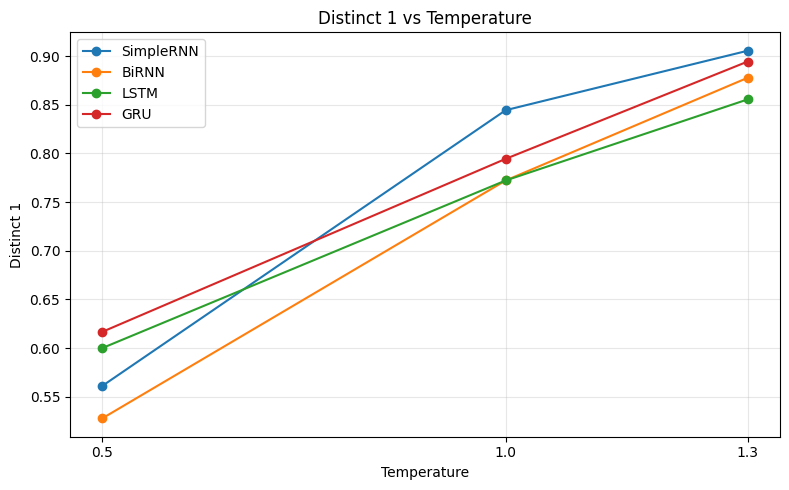

Saved: /content/sherlock_dataset/results/distinct_1_temperature.png


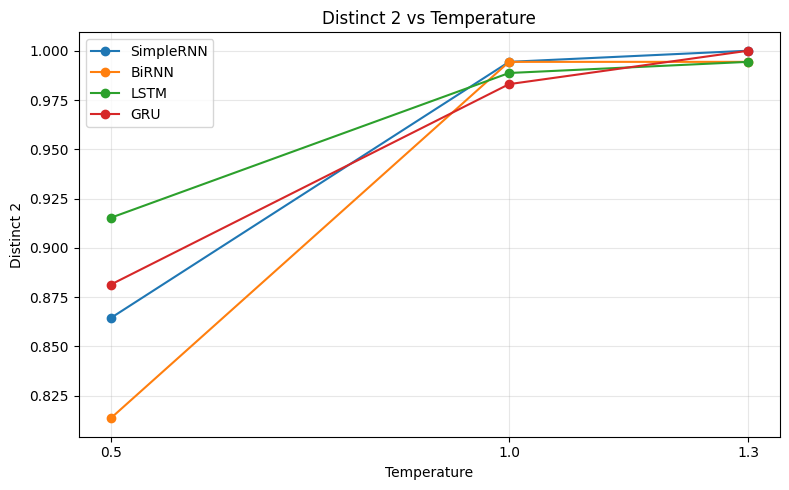

Saved: /content/sherlock_dataset/results/distinct_2_temperature.png


In [84]:

import matplotlib.pyplot as plt

for metric in ["distinct_1", "distinct_2"]:
    plt.figure(figsize=(8, 5))

    for model_type in MODEL_TYPES:
        subset = summary_metrics[
            summary_metrics["model"] == model_type
        ].sort_values("temperature")

        plt.plot(
            subset["temperature"],
            subset[metric],
            marker="o",
            label=model_type
        )

    plt.xlabel("Temperature")
    plt.ylabel(metric.replace("_", " ").title())
    plt.title(f"{metric.replace('_', ' ').title()} vs Temperature")
    plt.xticks(TEMPERATURES)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    plot_path = os.path.join(
        results_dir, f"{metric}_temperature.png"
    )
    plt.savefig(plot_path, dpi=150)
    plt.show()

    print("Saved:", plot_path)


### Analysis of Text Generation and Temperature

The effect of sampling temperature was evaluated using Distinct-1, Distinct-2, repeated-word rate, and repeated-bigram rate. Each of the four models generated text from the same three seed prompts at temperatures of 0.5, 1.0, and 1.3.

At a temperature of 0.5, the models generally exhibited lower lexical diversity and higher repetition. GRU achieved the highest average Distinct-1 score (0.622), while LSTM had the lowest (0.506). Lower temperatures produced more predictable continuations, although some samples remained repetitive and grammatically inconsistent.

Increasing the temperature to 1.0 generally increased lexical diversity. SimpleRNN achieved the highest Distinct-1 score at this temperature (0.839). At a temperature of 1.3, BiRNN achieved the highest Distinct-1 score (0.928), followed by SimpleRNN (0.900), with LSTM and GRU both scoring approximately 0.878. Distinct-2 reached 1.000 for all four models at temperature 1.3, indicating that no bigrams were repeated within the measured generated continuations in the averaged results.

However, lexical diversity alone does not establish text quality. Manual inspection showed that generated samples frequently lacked grammatical coherence and contextual consistency, including at higher temperatures. Temperature therefore presents a trade-off between predictable generation and lexical variety; greater diversity does not necessarily produce more meaningful text.

On the held-out test set, GRU achieved the lowest loss (5.7839), lowest perplexity (325.03), and highest next-word prediction accuracy (13.88%). It is therefore the strongest model by these quantitative metrics in this experiment. SimpleRNN had the shortest measured training time (approximately 0.63 minutes). These findings do not mean that GRU produced perfectly coherent text; its generated samples also showed limitations in grammar and context. The best overall model depends on both predictive performance and qualitative generation quality.

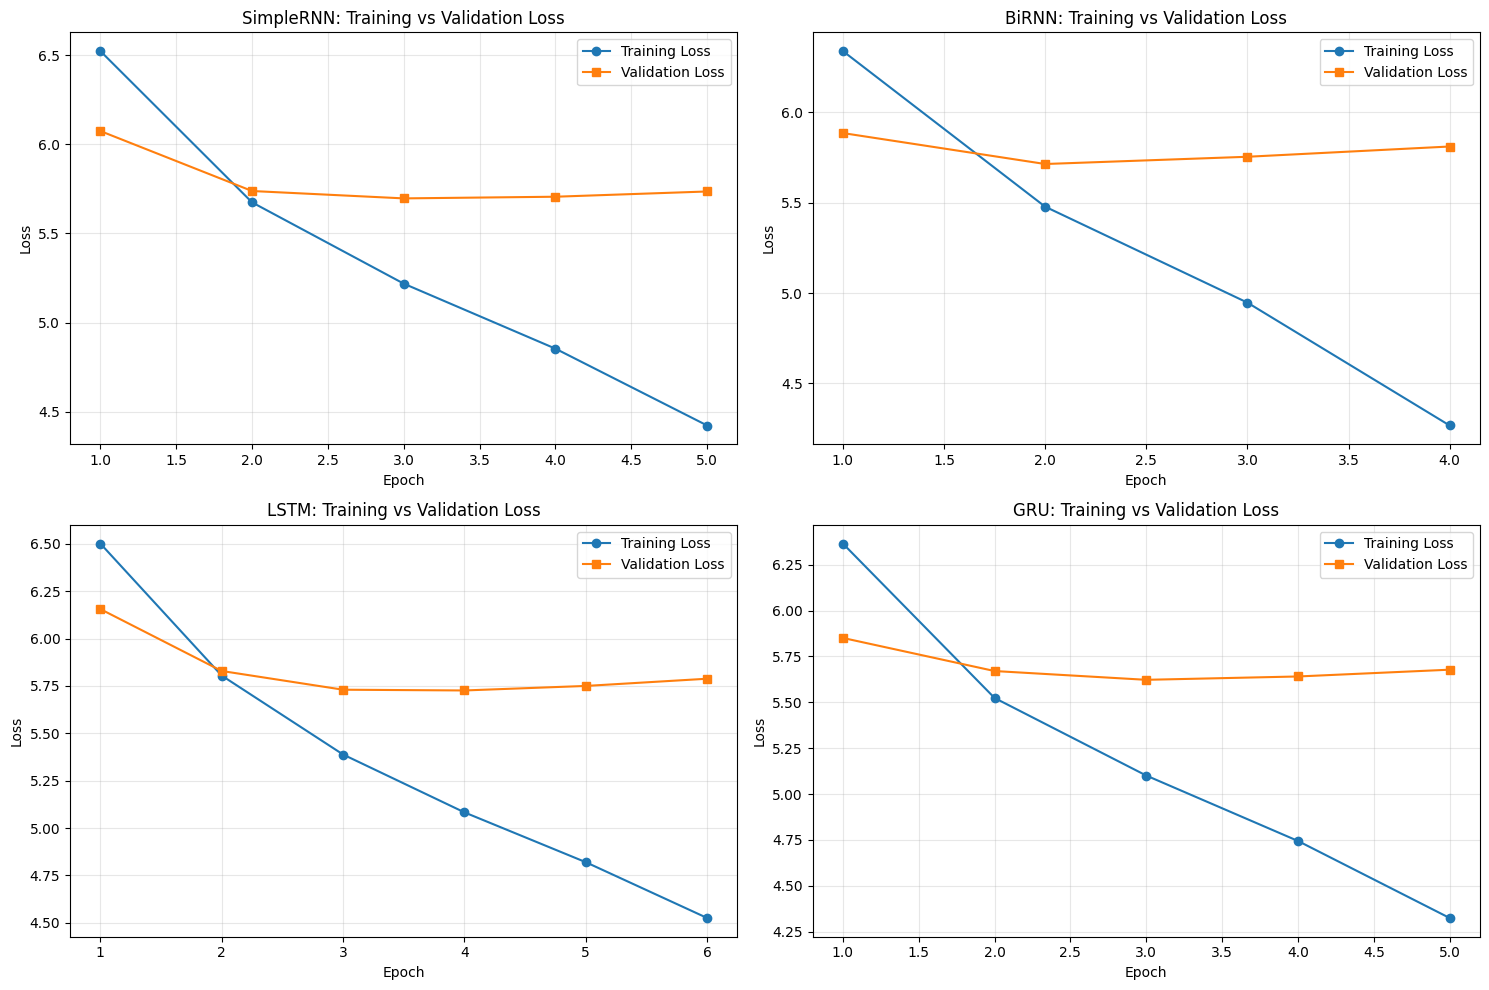

Saved: /content/sherlock_dataset/results/training_validation_loss.png


In [85]:

# Step 27: Compare training and validation loss across all models

import matplotlib.pyplot as plt
import os

results_dir = "/content/sherlock_dataset/results"
os.makedirs(results_dir, exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for ax, model_name in zip(axes, trained_models.keys()):
    # histories already stores each model's history as a dictionary
    history = histories[model_name]

    epochs = range(1, len(history["loss"]) + 1)

    ax.plot(epochs, history["loss"], marker="o", label="Training Loss")
    ax.plot(epochs, history["val_loss"], marker="s", label="Validation Loss")

    ax.set_title(f"{model_name}: Training vs Validation Loss")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()

loss_plot_path = os.path.join(
    results_dir, "training_validation_loss.png"
)

plt.savefig(loss_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", loss_plot_path)


In [86]:

# Step 28: Compare final test performance across all models

import pandas as pd
import matplotlib.pyplot as plt
import os

results_dir = "/content/sherlock_dataset/results"

# Load the saved test results
test_results_df = pd.read_csv(
    os.path.join(results_dir, "test_results.csv")
)

print("Test results:")
display(test_results_df.round(4))

# Identify the columns used for plotting
print("Available columns:", test_results_df.columns.tolist())


Test results:


,model,test_loss,test_perplexity,test_accuracy,evaluation_time_seconds,test_accuracy_percent
0,SimpleRNN,5.8583,350.1160,0.1308,0.9670,13.0820
1,BiRNN,5.8583,350.1345,0.1228,1.1750,12.2796
2,LSTM,5.9084,368.1343,0.1305,0.8997,13.0540
3,GRU,5.7861,325.7366,0.1357,0.8103,13.5672


Available columns: ['model', 'test_loss', 'test_perplexity', 'test_accuracy', 'evaluation_time_seconds', 'test_accuracy_percent']


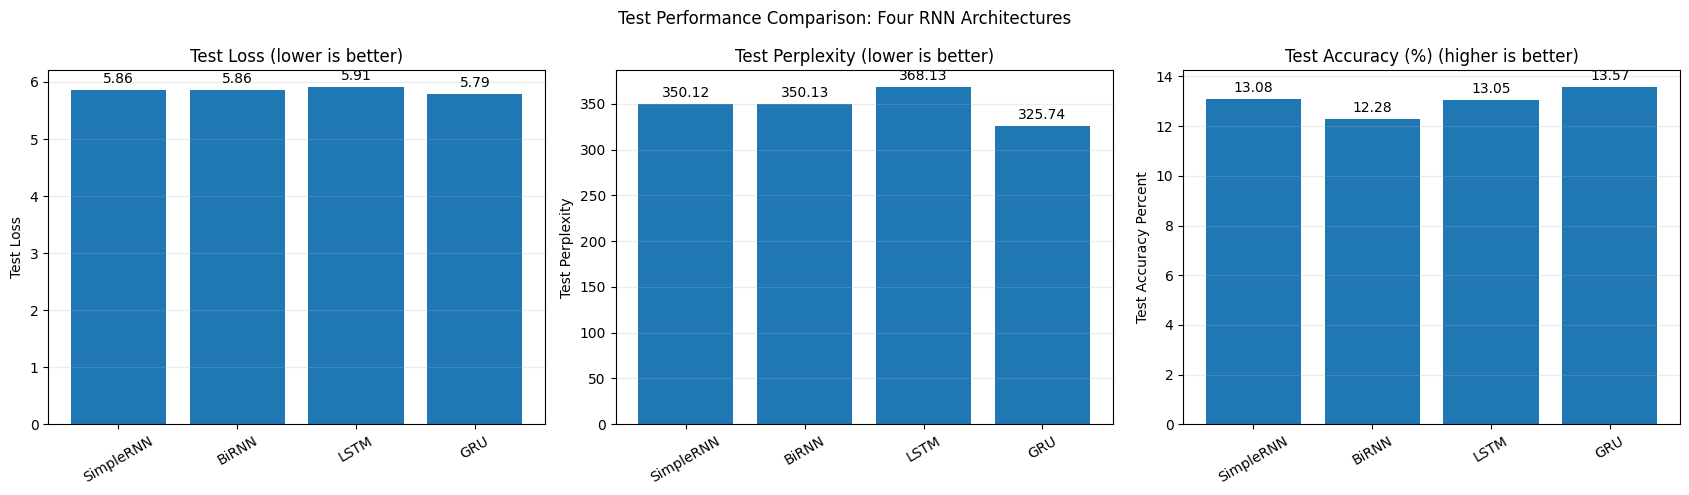

Saved: /content/sherlock_dataset/results/test_performance_comparison.png


In [87]:

# Step 28A: Visualize test performance of all four models

import matplotlib.pyplot as plt
import os

results_dir = "/content/sherlock_dataset/results"

# Sort models by their existing order in the results table
plot_df = test_results_df.copy()

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

metrics = [
    ("test_loss", "Test Loss (lower is better)"),
    ("test_perplexity", "Test Perplexity (lower is better)"),
    ("test_accuracy_percent", "Test Accuracy (%) (higher is better)")
]

for ax, (column, title) in zip(axes, metrics):
    bars = ax.bar(plot_df["model"], plot_df[column])
    ax.set_title(title)
    ax.set_ylabel(column.replace("_", " ").title())
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=0.25)

    # Display the value above each bar
    ax.bar_label(bars, fmt="%.2f", padding=3)

plt.suptitle("Test Performance Comparison: Four RNN Architectures")
plt.tight_layout()

chart_path = os.path.join(
    results_dir, "test_performance_comparison.png"
)

plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", chart_path)


In [88]:

# Step 28B: Rank models using test-set performance

ranking_df = test_results_df[
    ["model", "test_loss", "test_perplexity", "test_accuracy_percent"]
].copy()

ranking_df = ranking_df.sort_values(
    by="test_loss", ascending=True
).reset_index(drop=True)

ranking_df.insert(0, "loss_rank", range(1, len(ranking_df) + 1))

ranking_path = os.path.join(
    results_dir, "test_performance_ranking.csv"
)

ranking_df.to_csv(ranking_path, index=False)

print("Model ranking by test loss:")
display(ranking_df.round(4))

print("Saved:", ranking_path)


Model ranking by test loss:


,loss_rank,model,test_loss,test_perplexity,test_accuracy_percent
0,1,GRU,5.7861,325.7366,13.5672
1,2,SimpleRNN,5.8583,350.1160,13.0820
2,3,BiRNN,5.8583,350.1345,12.2796
3,4,LSTM,5.9084,368.1343,13.0540


Saved: /content/sherlock_dataset/results/test_performance_ranking.csv


In [89]:

# Step 30: Inspect and consolidate experiment results

import pandas as pd
import os

results_dir = "/content/sherlock_dataset/results"

# Load the saved experiment results
training_df = pd.read_csv(
    os.path.join(results_dir, "training_results.csv")
)

test_df = pd.read_csv(
    os.path.join(results_dir, "test_results.csv")
)

generation_summary_df = pd.read_csv(
    os.path.join(results_dir, "generation_metrics_summary.csv")
)

print("TRAINING RESULTS COLUMNS")
print(training_df.columns.tolist())
display(training_df.head())

print("\nTEST RESULTS COLUMNS")
print(test_df.columns.tolist())
display(test_df.head())

print("\nGENERATION SUMMARY")
print(generation_summary_df.columns.tolist())
display(generation_summary_df.head())


TRAINING RESULTS COLUMNS
['model', 'training_time_seconds', 'best_epoch', 'best_val_loss', 'best_val_accuracy', 'training_time_minutes']


,model,training_time_seconds,best_epoch,best_val_loss,best_val_accuracy,training_time_minutes
0,SimpleRNN,34.693890,3.0,5.696416,0.138922,0.578232
1,BiRNN,42.530150,2.0,5.714302,0.131292,0.708836
2,LSTM,59.689264,4.0,5.726010,0.137620,0.994821
3,GRU,51.091957,3.0,5.622463,0.143761,0.851533



TEST RESULTS COLUMNS
['model', 'test_loss', 'test_perplexity', 'test_accuracy', 'evaluation_time_seconds', 'test_accuracy_percent']


,model,test_loss,test_perplexity,test_accuracy,evaluation_time_seconds,test_accuracy_percent
0,SimpleRNN,5.858264,350.115971,0.130820,0.966982,13.082018
1,BiRNN,5.858317,350.134503,0.122796,1.174984,12.279556
2,LSTM,5.908448,368.134272,0.130540,0.899712,13.054027
3,GRU,5.786089,325.736556,0.135672,0.810286,13.567230



GENERATION SUMMARY
['model', 'temperature', 'distinct_1', 'distinct_2', 'repeated_word_rate', 'repeated_bigram_rate']


,model,temperature,distinct_1,distinct_2,repeated_word_rate,repeated_bigram_rate
0,BiRNN,0.5,0.527778,0.813559,0.472222,0.186441
1,BiRNN,1.0,0.772222,0.994350,0.227778,0.005650
2,BiRNN,1.3,0.877778,0.994350,0.122222,0.005650
3,GRU,0.5,0.616667,0.881356,0.383333,0.118644
4,GRU,1.0,0.794444,0.983051,0.205556,0.016949


In [90]:

# Step 31: Consolidate all experiment results

import pandas as pd
import os

results_dir = "/content/sherlock_dataset/results"

# 1. Prepare training results
training_clean = training_df[
    [
        "model",
        "training_time_minutes",
        "best_epoch",
        "best_val_loss",
        "best_val_accuracy"
    ]
].copy()

training_clean["best_val_accuracy_percent"] = (
    training_clean["best_val_accuracy"] * 100
)

training_clean.drop(columns=["best_val_accuracy"], inplace=True)

# 2. Prepare test results
test_clean = test_df[
    [
        "model",
        "test_loss",
        "test_perplexity",
        "test_accuracy_percent",
        "evaluation_time_seconds"
    ]
].copy()

# 3. Merge training and test results
model_comparison_df = pd.merge(
    training_clean,
    test_clean,
    on="model",
    how="inner"
)

# 4. Rank models by test loss
model_comparison_df["test_loss_rank"] = (
    model_comparison_df["test_loss"]
    .rank(method="min", ascending=True)
    .astype(int)
)

model_comparison_df = model_comparison_df.sort_values(
    "test_loss_rank"
).reset_index(drop=True)

# 5. Save consolidated model comparison
comparison_path = os.path.join(
    results_dir, "consolidated_model_comparison.csv"
)

model_comparison_df.to_csv(comparison_path, index=False)

print("CONSOLIDATED MODEL COMPARISON")
display(model_comparison_df.round(4))

print("\nSaved:", comparison_path)

# 6. Summarize generation metrics by model and temperature
generation_summary_path = os.path.join(
    results_dir, "generation_metrics_summary.csv"
)

generation_summary_df = generation_summary_df.sort_values(
    ["model", "temperature"]
).reset_index(drop=True)

generation_summary_df.to_csv(
    generation_summary_path, index=False
)

print("\nGENERATION DIVERSITY SUMMARY")
display(generation_summary_df.round(3))
print("\nSaved:", generation_summary_path)


CONSOLIDATED MODEL COMPARISON


,model,training_time_minutes,best_epoch,best_val_loss,best_val_accuracy_percent,test_loss,test_perplexity,test_accuracy_percent,evaluation_time_seconds,test_loss_rank
0,GRU,0.8515,3.0,5.6225,14.3761,5.7861,325.7366,13.5672,0.8103,1
1,SimpleRNN,0.5782,3.0,5.6964,13.8922,5.8583,350.1160,13.0820,0.9670,2
2,BiRNN,0.7088,2.0,5.7143,13.1292,5.8583,350.1345,12.2796,1.1750,3
3,LSTM,0.9948,4.0,5.7260,13.7620,5.9084,368.1343,13.0540,0.8997,4



Saved: /content/sherlock_dataset/results/consolidated_model_comparison.csv

GENERATION DIVERSITY SUMMARY


,model,temperature,distinct_1,distinct_2,repeated_word_rate,repeated_bigram_rate
0,BiRNN,0.5,0.528,0.814,0.472,0.186
1,BiRNN,1.0,0.772,0.994,0.228,0.006
2,BiRNN,1.3,0.878,0.994,0.122,0.006
3,GRU,0.5,0.617,0.881,0.383,0.119
4,GRU,1.0,0.794,0.983,0.206,0.017
5,GRU,1.3,0.894,1.000,0.106,0.000
6,LSTM,0.5,0.600,0.915,0.400,0.085
7,LSTM,1.0,0.772,0.989,0.228,0.011
8,LSTM,1.3,0.856,0.994,0.144,0.006
9,SimpleRNN,0.5,0.561,0.864,0.439,0.136



Saved: /content/sherlock_dataset/results/generation_metrics_summary.csv


In [91]:

# Step 32: Generate a final experiment summary

import os
import pandas as pd

results_dir = "/content/sherlock_dataset/results"

comparison = pd.read_csv(
    os.path.join(results_dir, "consolidated_model_comparison.csv")
)

generation = pd.read_csv(
    os.path.join(results_dir, "generation_metrics_summary.csv")
)

summary_path = os.path.join(results_dir, "experiment_summary.txt")

with open(summary_path, "w", encoding="utf-8") as f:
    f.write("SHERLOCK HOLMES NEXT-WORD GENERATION EXPERIMENT\n")
    f.write("=" * 55 + "\n\n")

    f.write("DATASET\n")
    f.write("Arthur Conan Doyle's The Adventures of Sherlock Holmes\n")
    f.write("12 stories from Project Gutenberg ebook #48320\n")
    f.write("Task: word-level next-token prediction\n\n")

    f.write("MODEL CONFIGURATION\n")
    f.write("Embedding dimension: 128\n")
    f.write("Recurrent units: 128\n")
    f.write("Maximum vocabulary size: 10,000\n")
    f.write("Input sequence length: 20 tokens\n")
    f.write("Batch size: 64\n")
    f.write("Optimizer: Adam\n")
    f.write("Initial learning rate: 0.001\n")
    f.write("Maximum epochs: 10, with early stopping\n\n")

    f.write("MODEL COMPARISON\n")
    f.write(comparison.to_string(index=False))
    f.write("\n\n")

    best = comparison.sort_values("test_loss").iloc[0]
    f.write("BEST MODEL BY TEST LOSS\n")
    f.write(f"Model: {best['model']}\n")
    f.write(f"Test loss: {best['test_loss']:.4f}\n")
    f.write(f"Test perplexity: {best['test_perplexity']:.2f}\n")
    f.write(
        f"Test accuracy: {best['test_accuracy_percent']:.2f}%\n\n"
    )

    f.write("GENERATION DIVERSITY BY MODEL AND TEMPERATURE\n")
    f.write(generation.to_string(index=False))
    f.write("\n\n")

    f.write("INTERPRETATION\n")
    f.write(
        "GRU achieved the best test loss, perplexity, and accuracy "
        "in this experiment. Increasing generation temperature generally "
        "increased lexical diversity and reduced repeated words. However, "
        "higher diversity does not necessarily imply better coherence. "
        "Generated samples should be evaluated qualitatively as well.\n"
    )

print("Saved:", summary_path)

with open(summary_path, "r", encoding="utf-8") as f:
    print(f.read())


Saved: /content/sherlock_dataset/results/experiment_summary.txt
SHERLOCK HOLMES NEXT-WORD GENERATION EXPERIMENT

DATASET
Arthur Conan Doyle's The Adventures of Sherlock Holmes
12 stories from Project Gutenberg ebook #48320
Task: word-level next-token prediction

MODEL CONFIGURATION
Embedding dimension: 128
Recurrent units: 128
Maximum vocabulary size: 10,000
Input sequence length: 20 tokens
Batch size: 64
Optimizer: Adam
Initial learning rate: 0.001
Maximum epochs: 10, with early stopping

MODEL COMPARISON
    model  training_time_minutes  best_epoch  best_val_loss  best_val_accuracy_percent  test_loss  test_perplexity  test_accuracy_percent  evaluation_time_seconds  test_loss_rank
      GRU               0.851533         3.0       5.622463                  14.376105   5.786089       325.736556              13.567230                 0.810286               1
SimpleRNN               0.578232         3.0       5.696416                  13.892248   5.858264       350.115971              13

In [92]:
# @title

# Step 33: Package experiment files and download the ZIP

import os
import zipfile
from google.colab import files

base_dir = "/content/sherlock_dataset"
results_dir = os.path.join(base_dir, "results")
zip_path = "/content/sherlock_holmes_experiment_results.zip"

# Files from dataset preparation
include_paths = [
    os.path.join(base_dir, "sherlock_holmes_corpus.txt"),
    os.path.join(base_dir, "sherlock_holmes_stories.txt"),
    os.path.join(base_dir, "processed", "next_word_sequences.npz"),
    os.path.join(base_dir, "processed", "tokenizer.pkl"),
]

# Add all saved experiment results and plots
for folder in [results_dir]:
    if os.path.isdir(folder):
        for filename in os.listdir(folder):
            full_path = os.path.join(folder, filename)
            if os.path.isfile(full_path):
                include_paths.append(full_path)

existing_paths = list(dict.fromkeys(
    path for path in include_paths if os.path.isfile(path)
))

missing_paths = [
    path for path in include_paths if not os.path.isfile(path)
]

# Create the ZIP
with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in existing_paths:
        archive.write(
            path,
            arcname=os.path.relpath(path, base_dir)
        )

print("ZIP created successfully!")
print(f"Files included: {len(existing_paths)}")
print(f"ZIP size: {os.path.getsize(zip_path) / (1024 * 1024):.2f} MB")

if missing_paths:
    print("\nFiles not found (skipped):")
    for path in missing_paths:
        print("-", path)

print("\nDownloading ZIP...")
files.download(zip_path)


ZIP created successfully!
Files included: 16
ZIP size: 1.67 MB



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>